## Trabajo Práctico 2: Aprendizaje Supervisado

## Clasificación de variedades de fríjoles mediante modelos de aprendizaje automático

**Asignatura:** Ciencia de Datos II

**Dataset:** Dry Bean Dataset

**Enfoque:** Clasificación supervisada

**Estudiante:** Sofía Quiroz Valencia

**Universidad:** Universidad Autónoma Latinoamericana (UNAULA)

### Introducción

El aprendizaje supervisado es una técnica de aprendizaje automático que permite construir modelos capaces de predecir resultados a partir de datos conocidos. En este trabajo se utilizará el Dry Bean Dataset, una base de datos que contiene características geométricas de diferentes variedades de fríjoles secos.

A partir de estas características, se busca comparar el desempeño de diferentes modelos de clasificación para identificar la variedad de cada fríjol. Para ello, se utilizarán métricas de evaluación y validación cruzada, con el propósito de determinar cuál modelo presenta un mejor rendimiento y capacidad de generalización.

### Descripción del dataset

El Dry Bean Dataset es un conjunto de datos público que contiene imágenes de siete variedades de fríjoles secos. A partir de estas imágenes se calcularon características numéricas relacionadas con el tamaño, el perímetro y la forma de cada fríjol.

La base de datos incluye variables como el área, la longitud de los ejes, la excentricidad y la relación de aspecto. La variable objetivo es `Class`, que identifica la variedad del fríjol.

Este conjunto de datos se utilizará para desarrollar un problema de clasificación multiclase, en el que los modelos aprenderán a relacionar las características numéricas con la variedad correspondiente.

### Objetivo general

Comparar el rendimiento de diferentes modelos clásicos de clasificación supervisada utilizando el Dry Bean Dataset, mediante métricas de evaluación y validación cruzada, para identificar el modelo con mejor desempeño y capacidad de generalización.

##### Importar librerías

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import roc_auc_score, make_scorer
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

##### Cargar base de datos

In [4]:
# Cargar el archivo Excel
df = pd.read_excel("C:/Documentos/OCTAVO SEMESTRE/Ciencia de Datos II/Datasets/Dry_Bean_Dataset.xlsx")

# Mostrar las primeras filas
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


#### Exploración inicial de los datos
Se revisan las dimensiones, los nombres de las columnas, los tipos de datos y las estadísticas descriptivas. Esto permite conocer la estructura del dataset antes de preparar los modelos.

In [6]:
# Dimensiones del dataset
print("Filas y columnas:", df.shape)

# Nombres de las columnas
print("\nColumnas:")
print(df.columns.tolist())

# Información general
df.info()

# Estadísticas descriptivas
df.describe()

Filas y columnas: (13611, 17)

Columnas:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  C

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


In [7]:
print("Valores faltantes por columna:")
print(df.isnull().sum())

print("\nFilas duplicadas:", df.duplicated().sum())

print("\nDistribución de las clases:")
print(df["Class"].value_counts())

Valores faltantes por columna:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Filas duplicadas: 68

Distribución de las clases:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


##### Visualización de los datos
Se elaboran gráficos para observar la distribución de las variedades, las características numéricas y las relaciones entre las variables.

##### Distribución de las variedades

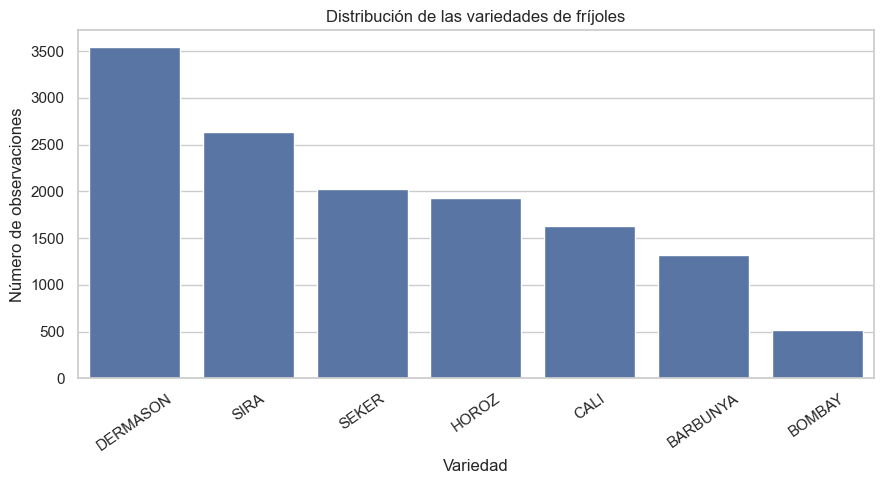

In [8]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Class", order=df["Class"].value_counts().index)

plt.title("Distribución de las variedades de fríjoles")
plt.xlabel("Variedad")
plt.ylabel("Número de observaciones")
plt.xticks(rotation=35)

plt.tight_layout()
plt.show()

##### Distribución de variables numéricas

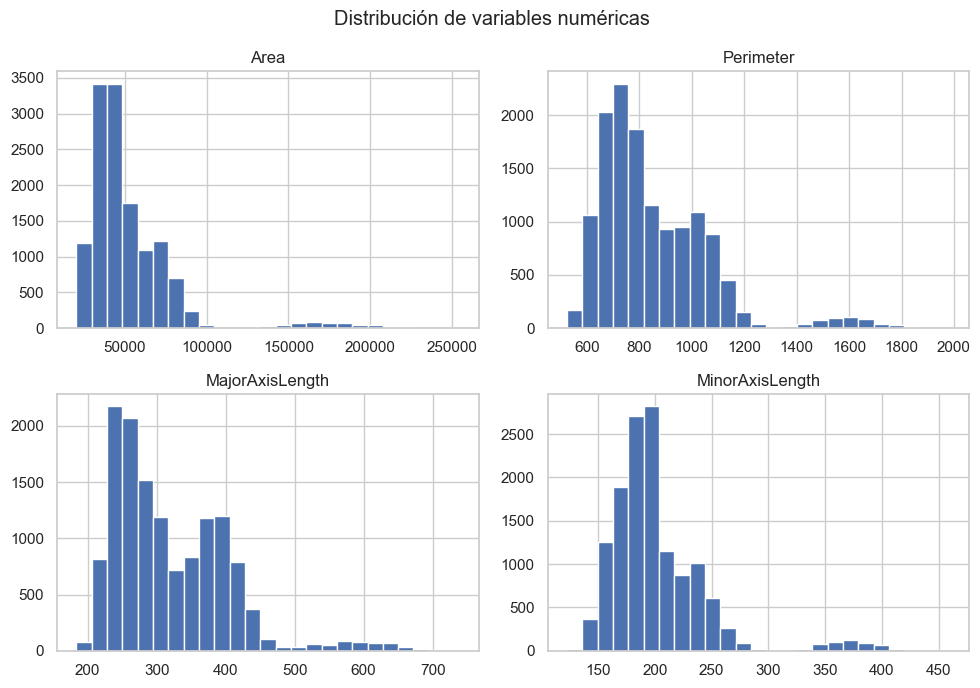

In [9]:
variables = ["Area", "Perimeter", "MajorAxisLength", "MinorAxisLength"]

df[variables].hist(figsize=(10, 7), bins=25)

plt.suptitle("Distribución de variables numéricas")
plt.tight_layout()
plt.show()

##### Matriz de correlación

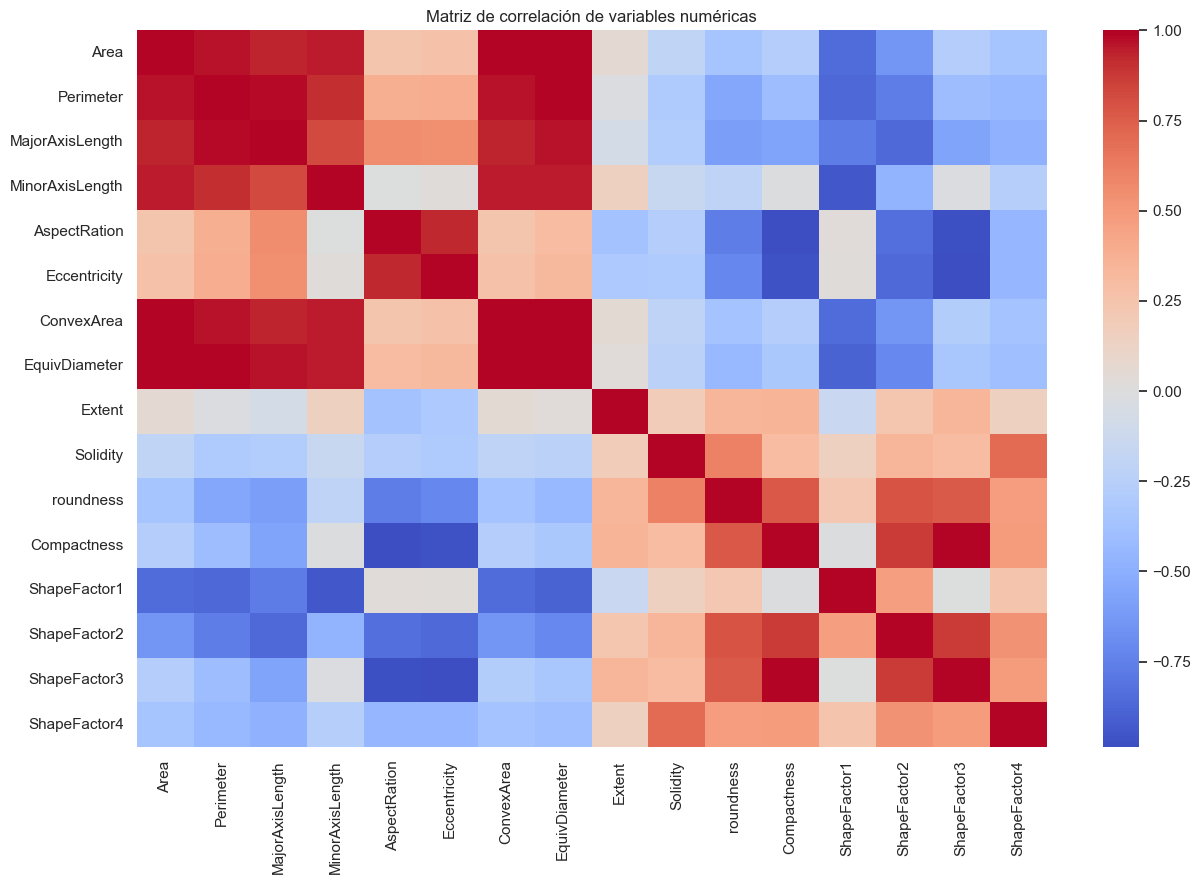

In [10]:
plt.figure(figsize=(13, 9))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()

##### Preparación de las variables
Se separan las variables predictoras, que contienen las características físicas de los fríjoles, y la variable objetivo Class, que identifica la variedad que se desea predecir.

In [12]:
# Variables predictoras
X = df.drop(columns=["Class"])

# Variable objetivo
y = df["Class"]

# Comprobar que las predictoras sean numéricas
print(X.dtypes)

print("\nNúmero de variables predictoras:", X.shape[1])
print("Número de clases:", y.nunique())

print("\nClases:")
print(sorted(y.unique()))

Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
dtype: object

Número de variables predictoras: 16
Número de clases: 7

Clases:
['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


##### División del dataset
Los datos se dividen en entrenamiento, validación y prueba, utilizando una proporción aproximada de 60 %, 20 % y 20 %. Se aplica una división estratificada para conservar la proporción de las variedades en cada conjunto.

In [13]:
# Primera división: 60% entrenamiento y 40% restante
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Segunda división: 20% validación y 20% prueba
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test.shape)


Entrenamiento: (8166, 16)
Validación: (2722, 16)
Prueba: (2723, 16)


##### Construcción de los modelos
Se seleccionan tres modelos clásicos de clasificación: regresión logística, KNN y árbol de decisión. Se utiliza un pipeline con StandardScaler para estandarizar las variables numéricas durante el entrenamiento.

In [14]:
modelos = {
    "Regresión logística": LogisticRegression(),
    "KNN": KNeighborsClassifier(),
    "Árbol de decisión": DecisionTreeClassifier()
}

pipelines = {}

for nombre, modelo in modelos.items():

    pipelines[nombre] = Pipeline([
        ("escalador", StandardScaler()),
        ("modelo", modelo)
    ])

print("Los tres pipelines están preparados.")

Los tres pipelines están preparados.


##### Definición de la métrica ROC AUC
Se define una función para calcular el ROC AUC multiclase mediante el enfoque One-vs-Rest y el promedio macro. Esta será la métrica principal para comparar los modelos.

In [15]:
def calcular_auc(modelo, X, y):
    probabilidades = modelo.predict_proba(X)

    return roc_auc_score(
        y,
        probabilidades,
        labels=modelo.classes_,
        multi_class="ovr",
        average="macro"
    )

##### Entrenamiento y evaluación inicial
Cada modelo se entrena con los datos de entrenamiento y se evalúa tanto en entrenamiento como en validación. Los resultados se guardan en una tabla para facilitar la comparación.

In [17]:
resultados_iniciales = []

for nombre, pipeline in pipelines.items():

    # Entrenar con el conjunto de entrenamiento
    pipeline.fit(X_train, y_train)

    # Métrica en entrenamiento
    auc_train = calcular_auc(pipeline, X_train, y_train)

    # Métrica en validación
    auc_val = calcular_auc(pipeline, X_val, y_val)

    resultados_iniciales.append({
        "Modelo": nombre,
        "ROC AUC entrenamiento": auc_train,
        "ROC AUC validación": auc_val
    })

tabla_inicial = pd.DataFrame(resultados_iniciales)

tabla_inicial.round(4)

,Modelo,ROC AUC entrenamiento,ROC AUC validación
0,Regresión logística,0.9951,0.9951
1,KNN,0.9979,0.9870
2,Árbol de decisión,1.0000,0.9470


##### Validación cruzada de cinco particiones
Se aplica validación cruzada estratificada con cinco folds sobre el conjunto de entrenamiento. Se registra el ROC AUC de cada partición y se calculan el promedio y la desviación estándar para evaluar el rendimiento y la estabilidad de cada modelo.

In [18]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": make_scorer(
        roc_auc_score,
        response_method="predict_proba",
        multi_class="ovr",
        average="macro",
        labels=np.unique(y_train)
    )
}

resultados_cv = []

for nombre, pipeline in pipelines.items():

    resultados = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1
    )

    scores = resultados["test_roc_auc"]

    fila = {
        "Modelo": nombre,
        "Fold 1": scores[0],
        "Fold 2": scores[1],
        "Fold 3": scores[2],
        "Fold 4": scores[3],
        "Fold 5": scores[4],
        "Promedio CV": scores.mean(),
        "Desviación estándar CV": scores.std()
    }

    resultados_cv.append(fila)

tabla_cv = pd.DataFrame(resultados_cv)

tabla_cv.round(4)

,Modelo,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Promedio CV,Desviación estándar CV
0,Regresión logística,0.9957,0.9946,0.9955,0.9953,0.9934,0.9949,0.0008
1,KNN,0.9866,0.9801,0.9881,0.9869,0.9835,0.9850,0.0029
2,Árbol de decisión,0.9529,0.9397,0.9477,0.9422,0.9465,0.9458,0.0046


##### Tabla comparativa de resultados
Se integran los resultados de entrenamiento, validación y validación cruzada para observar las diferencias entre los tres modelos.

In [19]:
tabla_comparativa = tabla_inicial.merge(
    tabla_cv,
    on="Modelo"
)

tabla_comparativa.round(4)

,Modelo,ROC AUC entrenamiento,ROC AUC validación,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Promedio CV,Desviación estándar CV
0,Regresión logística,0.9951,0.9951,0.9957,0.9946,0.9955,0.9953,0.9934,0.9949,0.0008
1,KNN,0.9979,0.9870,0.9866,0.9801,0.9881,0.9869,0.9835,0.9850,0.0029
2,Árbol de decisión,1.0000,0.9470,0.9529,0.9397,0.9477,0.9422,0.9465,0.9458,0.0046


##### Gráfico de comparación
El siguiente gráfico permite comparar visualmente el ROC AUC de entrenamiento, validación y validación cruzada.

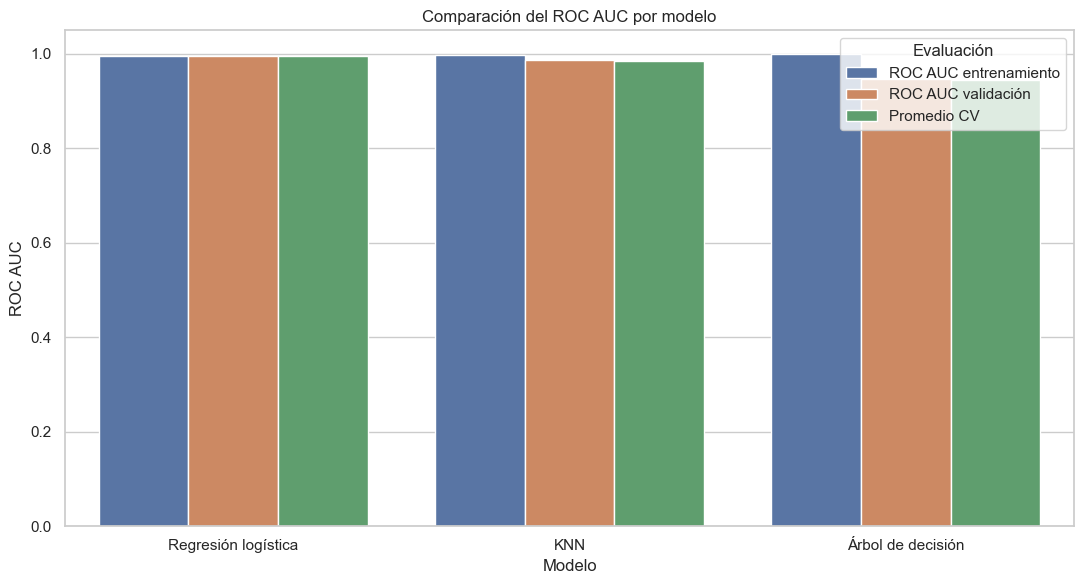

In [20]:
tabla_grafico = tabla_comparativa.melt(
    id_vars="Modelo",
    value_vars=[
        "ROC AUC entrenamiento",
        "ROC AUC validación",
        "Promedio CV"
    ],
    var_name="Evaluación",
    value_name="ROC AUC"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=tabla_grafico,
    x="Modelo",
    y="ROC AUC",
    hue="Evaluación"
)

plt.title("Comparación del ROC AUC por modelo")
plt.ylim(0, 1.05)
plt.ylabel("ROC AUC")
plt.xlabel("Modelo")
plt.legend(title="Evaluación")
plt.tight_layout()
plt.show()

##### Variabilidad entre folds
Se construye un diagrama de caja para observar las diferencias en el ROC AUC de cada modelo a través de las cinco particiones.

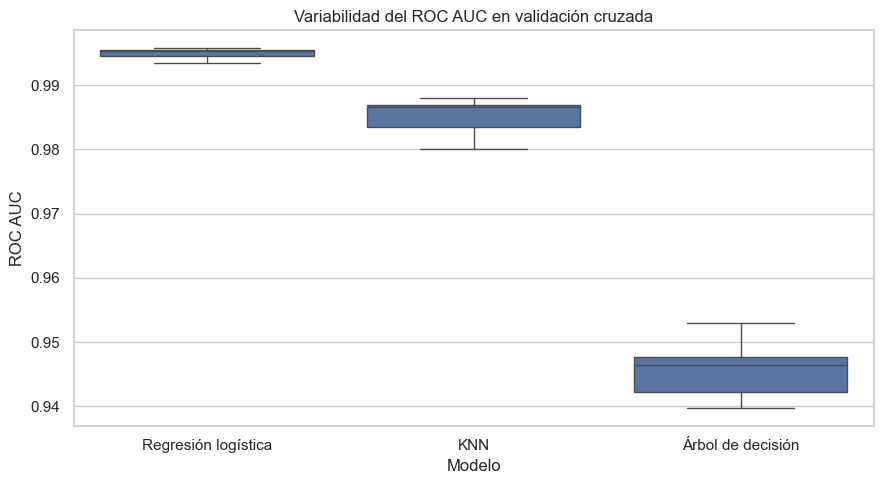

In [21]:
tabla_folds = tabla_cv.melt(
    id_vars="Modelo",
    value_vars=["Fold 1", "Fold 2", "Fold 3", "Fold 4", "Fold 5"],
    var_name="Fold",
    value_name="ROC AUC"
)

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=tabla_folds,
    x="Modelo",
    y="ROC AUC"
)

plt.title("Variabilidad del ROC AUC en validación cruzada")
plt.tight_layout()
plt.show()

### Análisis de validación cruzada y generalización

**1. Comparación entre validación cruzada y conjunto de validación**

La regresión logística obtuvo un ROC AUC de 0.9951 en validación y de 0.9949 en validación cruzada, mostrando resultados muy similares. KNN obtuvo 0.9870 en validación y 0.9850 en validación cruzada, mientras que el árbol de decisión presentó 0.9470 y 0.9458, respectivamente. Esto indica que los resultados de validación son consistentes con los obtenidos mediante validación cruzada y que la regresión logística presenta el mejor desempeño.

**2. ¿Qué modelo generaliza mejor?**

La regresión logística parece generalizar mejor, ya que obtuvo los valores más altos de ROC AUC en validación y validación cruzada, con poca diferencia entre ambos resultados. Por su parte, el árbol de decisión obtuvo un resultado perfecto en entrenamiento, pero su desempeño disminuyó en los demás conjuntos, lo que puede indicar sobreajuste. Por esta razón, la regresión logística es la opción más adecuada entre los modelos evaluados.

##### Selección del mejor modelo
Se identifica el modelo que obtuvo el mayor promedio de ROC AUC en validación cruzada. La decisión también debe considerar los resultados de validación y la variabilidad entre folds.

In [23]:
mejor_nombre = tabla_comparativa.loc[
    tabla_comparativa["Promedio CV"].idxmax(),
    "Modelo"
]

print("Modelo seleccionado:", mejor_nombre)

print(
    "Promedio ROC AUC CV:",
    round(
        tabla_comparativa.loc[
            tabla_comparativa["Modelo"] == mejor_nombre,
            "Promedio CV"
        ].iloc[0],
        4
    )
)

Modelo seleccionado: Regresión logística
Promedio ROC AUC CV: 0.9949


##### Evaluación final en el conjunto de prueba
Una vez seleccionado el modelo, se entrena nuevamente con el conjunto de entrenamiento y se evalúa sobre los datos de prueba, que se han mantenido separados durante las etapas anteriores.

In [24]:
mejor_modelo = pipelines[mejor_nombre]

# Entrenamiento final con el conjunto de entrenamiento
mejor_modelo.fit(X_train, y_train)

# Evaluación final en prueba
auc_test = calcular_auc(
    mejor_modelo,
    X_test,
    y_test
)

print("Modelo seleccionado:", mejor_nombre)
print("ROC AUC en prueba:", round(auc_test, 4))

Modelo seleccionado: Regresión logística
ROC AUC en prueba: 0.9943


##### Comparación entre validación cruzada y prueba
Se compara el promedio de ROC AUC obtenido en validación cruzada con el resultado del conjunto de prueba para analizar si el desempeño se mantiene en datos independientes.

In [25]:
promedio_cv = tabla_comparativa.loc[
    tabla_comparativa["Modelo"] == mejor_nombre,
    "Promedio CV"
].iloc[0]

print("Promedio ROC AUC CV:", round(promedio_cv, 4))
print("ROC AUC prueba:", round(auc_test, 4))
print("Diferencia absoluta:", round(abs(promedio_cv - auc_test), 4))

Promedio ROC AUC CV: 0.9949
ROC AUC prueba: 0.9943
Diferencia absoluta: 0.0006


### Evaluación final en el conjunto de prueba

**1. Selección y entrenamiento del modelo**

Se seleccionó la regresión logística porque obtuvo el mayor promedio de ROC AUC en la validación cruzada. Posteriormente, se entrenó nuevamente utilizando el conjunto de entrenamiento para evaluar su desempeño final con datos que no había utilizado durante el ajuste.

**2. Rendimiento en el conjunto de prueba**

El modelo obtuvo un ROC AUC de 0.9943 en el conjunto de prueba, lo que demuestra una alta capacidad para distinguir correctamente entre las variedades de fríjoles.

**3. Comparación con la validación cruzada**

El ROC AUC promedio de validación cruzada fue de 0.9949, mientras que en el conjunto de prueba fue de 0.9943. La diferencia fue de 0.0006, por lo que el resultado final es muy cercano al esperado. Esto indica que el modelo mantiene un desempeño estable y presenta una buena capacidad de generalización.

##### Matriz de confusión y reporte de clasificación
Se complementa la evaluación mediante una matriz de confusión y un reporte de clasificación. Estas herramientas permiten observar los aciertos y errores del modelo para cada variedad de fríjol.

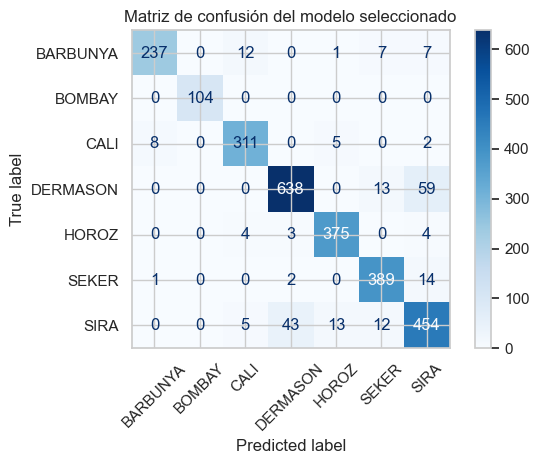

In [26]:
y_pred = mejor_modelo.predict(X_test)

matriz = confusion_matrix(
    y_test,
    y_pred,
    labels=mejor_modelo.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=mejor_modelo.classes_
)

disp.plot(
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de confusión del modelo seleccionado")
plt.tight_layout()
plt.show()

#### Conclusiones
Se compararon tres modelos de clasificación: regresión logística, KNN y árbol de decisión, utilizando la métrica ROC AUC para evaluar su desempeño. Los resultados muestran que la regresión logística fue el mejor modelo, con un promedio de validación cruzada de 0.9949, seguida de KNN con 0.9850 y el árbol de decisión con 0.9458.
Además, la regresión logística obtuvo un ROC AUC de 0.9943 en el conjunto de prueba, un resultado muy cercano al promedio de validación cruzada, cuya diferencia fue de apenas 0.0006. Esto indica que el modelo presenta un desempeño estable y una buena capacidad de generalización sobre datos nuevos.
Por otro lado, el árbol de decisión presentó un ROC AUC de 1.0000 en entrenamiento, pero resultados inferiores en validación y validación cruzada, lo que puede indicar sobreajuste. En conclusión, se seleccionó la regresión logística porque obtuvo los mejores resultados generales y mantuvo un desempeño alto y consistente, por lo que es el modelo más adecuado entre los tres evaluados para clasificar las variedades de fríjoles.